In [1]:
# ==========================================
# =                  SETUP                 =
# ==========================================
import sys
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

if os.path.abspath('..') not in sys.path:
    sys.path.append(os.path.abspath('..'))

from src.dataset import get_data_splits, get_dataloaders
from src.augmentation import get_valid_transform_clahe
from src.models import get_resnet18_modified, get_efficientnet_b0_modified, get_cct_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAIN_DIR = "../data/GTSRB/Training"

train_df, val_df = get_data_splits(TRAIN_DIR)
_, val_loader = get_dataloaders(
    train_df, val_df, 
    train_transform=get_valid_transform_clahe(), 
    val_transform=get_valid_transform_clahe(), 
    batch_size=64
)

print(f"Dataloader de Validação carregado com sucesso! Total de imagens: {len(val_df)}")

Dataloader de Validação carregado com sucesso! Total de imagens: 5303


In [2]:
# ==========================================
# =       FUNÇÃO PARA CRIAR PREVISÕES      =
# ==========================================
def get_predictions(model, dataloader):
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    return np.array(all_labels), np.array(all_preds)

In [ ]:
# ==========================================
# =  CARREGAR O MELHOR MODELO E AVALIAR    =
# ==========================================
# Exemplo: Carregar o EfficientNetB0 do Modelo 5 (MixUp)
model = get_efficientnet_b0_modified(num_classes=43, pretrained=False).to(device)
model.load_state_dict(torch.load("../checkpoints/modelo5_mixup_efficientnet.pth"))

print("A gerar previsões para o Modelo 5 no Validation Set...")
y_true, y_pred = get_predictions(model, val_loader)

A gerar previsões para o Modelo 5 no Validation Set...


# JUSTIFICAÇÃO DA ESCOLHA:
Optei pelo Modelo 5 (EfficientNetB0 + MixUp) porque a sua curva de aprendizagem 
prova uma excelente prevenção de overfitting. O treino difícil concluiu uma validação 
de 99.94%, aliando a alta precisão a uma arquitetura mais leve 

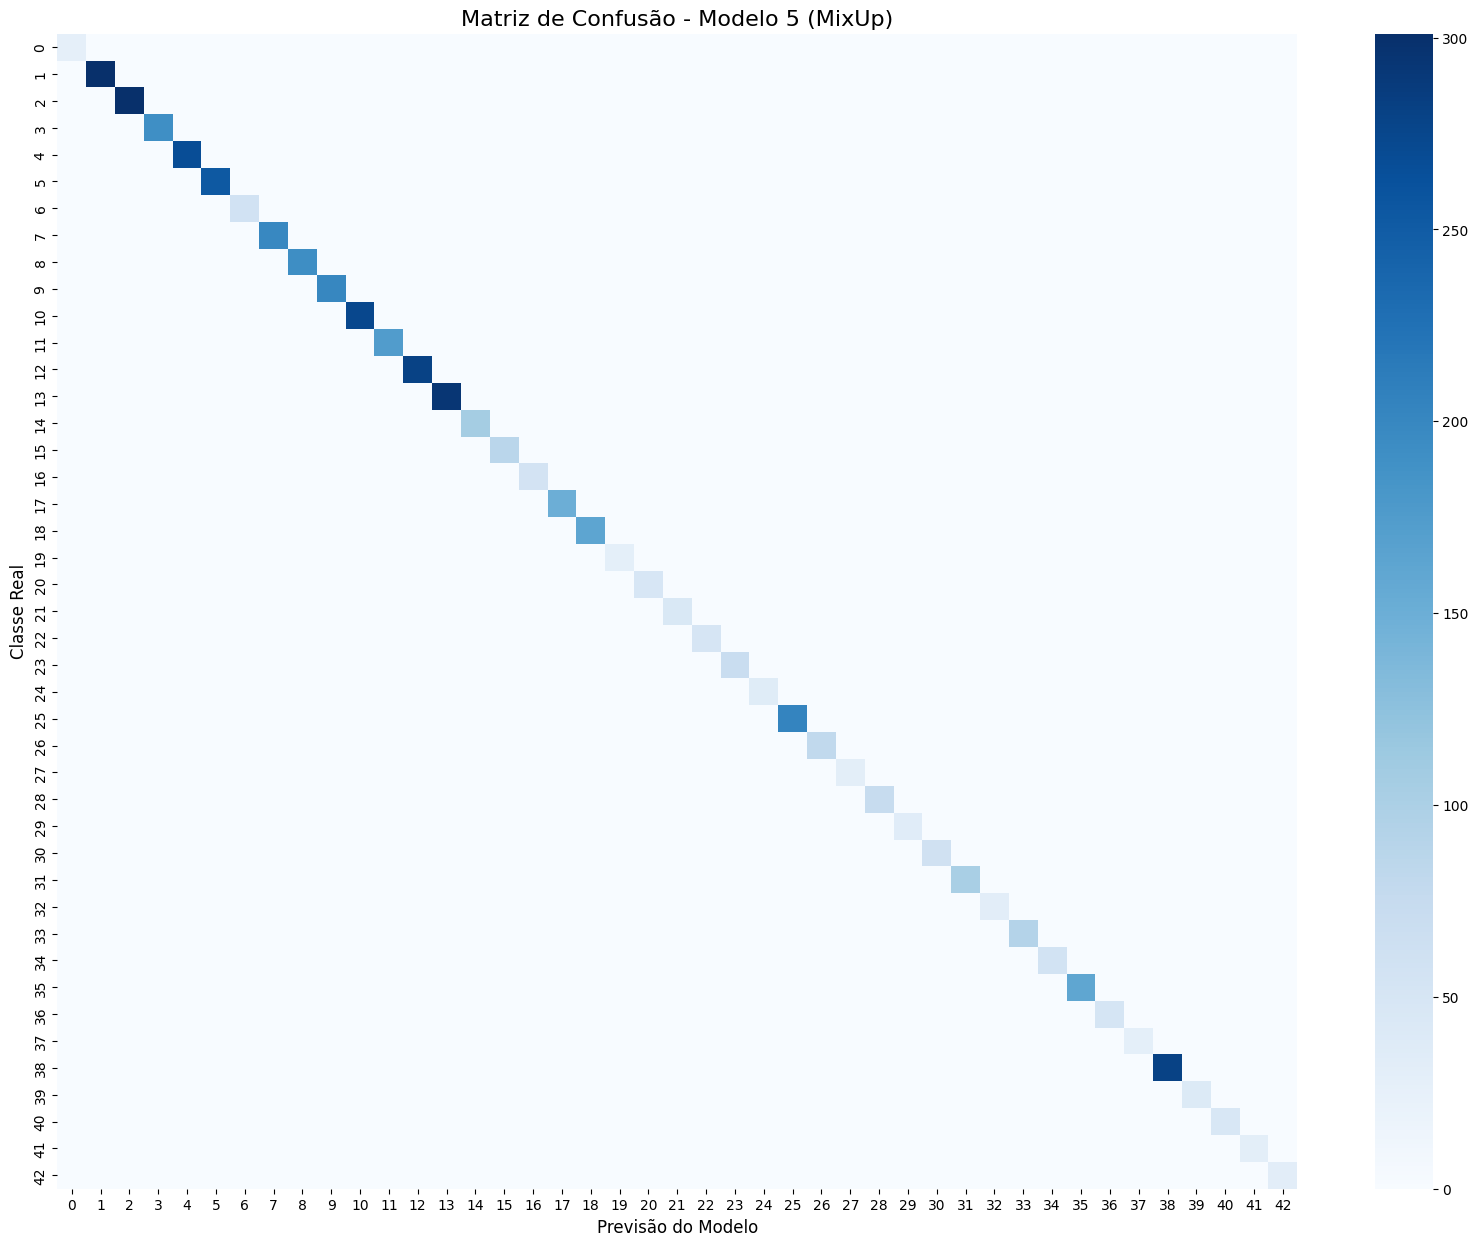

Total de erros na validação: 3 de 5303 imagens.


In [ ]:
# ==========================================
# =         MATRIZ DE CONFUSÃO             =
# ==========================================
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(20, 15))
sns.heatmap(cm, annot=False, cmap='Blues', fmt='g')
plt.title('Matriz de Confusão - Modelo 5 (MixUp)', fontsize=16)
plt.xlabel('Previsão do Modelo', fontsize=12)
plt.ylabel('Classe Real', fontsize=12)
plt.show()

erros = np.where(y_true != y_pred)[0]
print(f"Total de erros na validação: {len(erros)} de {len(y_true)} imagens.")

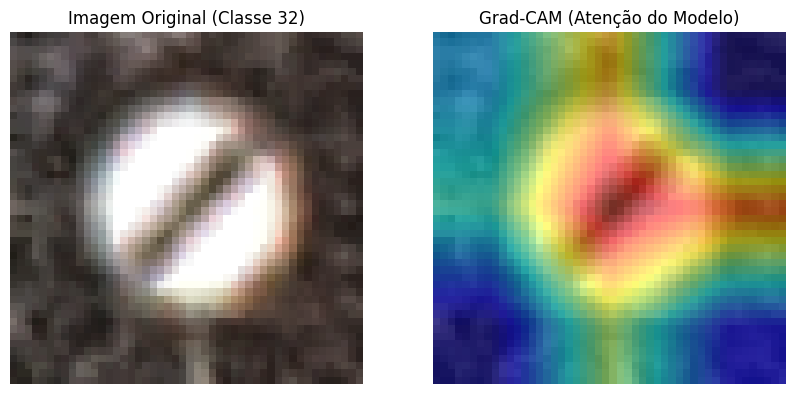

In [ ]:
# ==========================================
# =               GRAD-CAM                 =
# ==========================================
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Escolher a camada alvo (na EfficientNetB0 é a última convolução)
target_layers = [model.features[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

# Pegar numa imagem de validação aleatória (índice 10)
img_tensor, label = val_loader.dataset[10]
input_tensor = img_tensor.unsqueeze(0).to(device)

# Criar máscara
targets = [ClassifierOutputTarget(label.item())]
grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

# Desnormalizar imagem para visualização
img_show = img_tensor.numpy().transpose(1, 2, 0)
mean, std = np.array([0.3403, 0.3121, 0.3214]), np.array([0.2724, 0.2608, 0.2669])
img_show = std * img_show + mean
img_show = np.clip(img_show, 0, 1)

# Sobrepor mapa de calor
cam_image = show_cam_on_image(img_show, grayscale_cam, use_rgb=True)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_show)
plt.title(f"Imagem Original (Classe {label.item()})")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cam_image)
plt.title("Grad-CAM (Atenção do Modelo)")
plt.axis('off')
plt.show()